In [12]:
import pandas as pd #Imports the Pandas library.
import numpy as np
import matplotlib.pyplot as plt #plotting graphs
from sklearn.preprocessing import MinMaxScaler # normalizes values to specified range
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential #arrange neural network layers in order
from tensorflow.keras.layers import LSTM, Dense # final numerical prediction

import zipfile #imports zip file handling module

with zipfile.ZipFile("/content/power.zip", "r") as z: #opens file in read mode
    z.extractall("/content/power_data")  # extracts the file

# Read the dataset into pndas dataframe called df
df = pd.read_csv(
    "/content/power_data/household_power_consumption.txt",
    sep=";",    #columns are separated by colons
    na_values="?",   #treats ? as missing values
    low_memory=False   #helps pandas infer the column types as whole rather than dividing it into smaller chunks
)

# Prepare date, time and consumption
df["DateTime"] = pd.to_datetime(    #converts dte & time columns into one datetime column
    df["Date"] + " " + df["Time"], dayfirst=True, errors="coerce")
df["Global_active_power"] = pd.to_numeric( #converts g_a_p into numeric values
    df["Global_active_power"], errors="coerce")  #coerce treats the invalid data as missing values

df = df.dropna(subset=["DateTime", "Global_active_power"]) #removes missing values
df = df.drop_duplicates("DateTime").sort_values("DateTime")

# Find 10,000 consecutive valid minutes
df = df.set_index("DateTime")
df = df[df.index.to_series().diff().eq(pd.Timedelta(minutes=1)) |
        df.index.to_series().diff().isna()]
# if the minute equals to 1.  finds the missing values
groups = df.index.to_series().diff().ne(pd.Timedelta(minutes=1)).cumsum()
# finds where the next continuos group is
blocks = [g for _, g in df.groupby(groups) if len(g) >= 10000]

if not blocks:
    raise ValueError("No block of 10,000 consecutive valid minutes found.")

data = blocks[0]["Global_active_power"].iloc[:10000].values.reshape(-1, 1)

print("Records loaded:", len(data))

Records loaded: 10000


In [13]:
split = int(0.8 * len(data))

scaler = MinMaxScaler()
train = scaler.fit_transform(data[:split])
test = scaler.transform(data[split:])

all_data = np.vstack([train, test])
X, y = [], []

for i in range(60, len(all_data)):
    X.append(all_data[i-60:i])
    y.append(all_data[i])

X, y = np.array(X), np.array(y)

X_train, y_train = X[:split-60], y[:split-60]
X_test, y_test = X[split-60:], y[split-60:]

print("Training sequences:", len(X_train))
print("Testing sequences:", len(X_test))

Training sequences: 7940
Testing sequences: 2000


In [14]:
model = Sequential([
    LSTM(32, input_shape=(60, 1)),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")
model.fit(X_train, y_train, epochs=5, batch_size=64)

print("Training completed")

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0087
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0061
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0057
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0054
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0053
Training completed


In [15]:
pred = model.predict(X_test)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(pred)

print("MAE:", round(mean_absolute_error(actual, predicted), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 4))

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
MAE: 0.1924
RMSE: 0.326


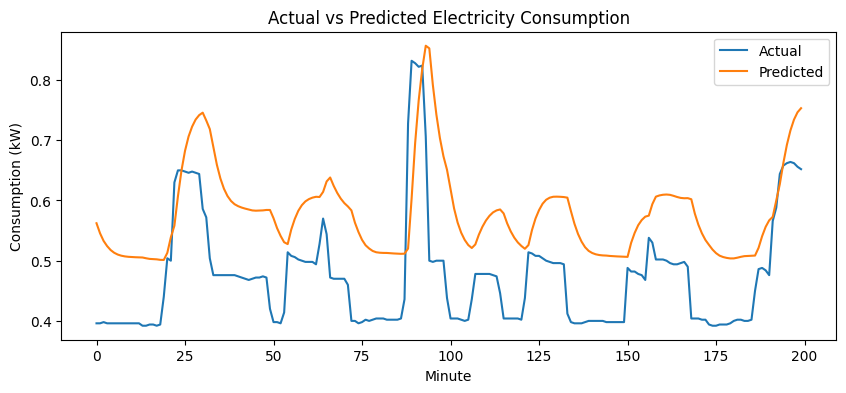

   Actual (kW)  Predicted (kW)
0        0.236           0.356
1        0.234           0.354
2        0.232           0.352
3        0.354           0.349
4        0.334           0.378


In [16]:
plt.figure(figsize=(10, 4))
plt.plot(actual[:200], label="Actual")
plt.plot(predicted[:200], label="Predicted")
plt.xlabel("Minute")
plt.ylabel("Consumption (kW)")
plt.title("Actual vs Predicted Electricity Consumption")
plt.legend()
plt.show()

print(pd.DataFrame({
    "Actual (kW)": actual[-5:].flatten(),
    "Predicted (kW)": predicted[-5:].flatten()
}).round(3))